# 2PCF Analysis — Switzerland — Transit Stops

Cross-2PCF calibration model.

**Original run (March 2026).** The outputs of this notebook are the run that gives the row `Swiss Stops` of Table 1 of the paper and of `out/00_dataset_calibration_reference.csv`. They are kept as a record. The same chain is written once in `src/calibration.py` (notebook `00_dataset_calibration` and `scripts/calibrate_all.py`). The random catalogues of the 2PCF are not seeded, so a new run gives slightly different values.

## 0. Imports and Setup

In [1]:
from joblib import Parallel, delayed
import multiprocessing as mp
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
import seaborn as sns
from shapely.geometry import MultiPolygon
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from tqdm import tqdm

root = Path("../../../").resolve()
sys.path.insert(0, str(root / "src"))

import methods_two_point_correlation as mtpc

# Helper functions (SP model, 2PCF utilities, cross-2PCF worker)
from sp_helpers import (
    soneira_peebles_border, get_inside_points, build_sp_model,
    power_law, fit_2pcf, _xi_mean, _align, _pcf_safe,
    _random_in_territory, _run_cross_pcf,
)

n_jobs = max(1, mp.cpu_count() - 2)
print(f"Imports OK  —  parallel workers: {n_jobs}  (CPUs: {mp.cpu_count()})")

Imports OK  —  parallel workers: 22  (CPUs: 24)


## 1. Load Switzerland Territory

In [2]:
name = "Switzerland"
data_dir = root / "data"
path_border = data_dir / "clean_transport_dataset" / name / "switzerland_nat_earth.geojson"

crs = mtpc.crs_selector(name)

gdf_edge_raw = gpd.read_file(path_border)
geom = gdf_edge_raw.geometry.iloc[0]
largest_poly = max(geom.geoms, key=lambda p: p.area) if isinstance(geom, MultiPolygon) else geom
gdf_edge_raw = gpd.GeoDataFrame(geometry=[largest_poly], crs=gdf_edge_raw.crs)
gdf_edge = gdf_edge_raw.to_crs(crs)

R_ref = 0.5 * gdf_edge.length.sum() / (2 * np.pi)

print(f"CRS          : {crs}")
print(f"Area         : {gdf_edge.area.sum()/1e6:.0f} km²")
print(f"Perimeter    : {gdf_edge.length.sum()/1e3:.0f} km")
print(f"R_ref        : {R_ref/1e3:.1f} km")

CRS          : EPSG:21781
Area         : 41439 km²
Perimeter    : 1479 km
R_ref        : 117.7 km


## 2. Dataset Selection

In [3]:
# ── Dataset ──────────────────────────────────────────────────────────────────
data_type          = "Stops"
path_csv           = data_dir / "clean_transport_dataset" / name / "swiss_stops.csv"
threshold_variable = "population_density"
threshold          = 1

# ── 2PCF parameters ──────────────────────────────────────────────────────────
N_run            = 5
size             = 7000
k                = 3
rmax             = 160000.0
scale            = "log"
nbins            = 20
bootstrap_size   = 10_000
bootstrap_N_real = 10

print(f"Dataset: {name} — {data_type}")
print(f"CSV    : {path_csv.name}")

Dataset: Switzerland — Stops
CSV    : swiss_stops.csv


## 3. Load Data — Compute 2PCF and Fit γ

N = 93,288 data points


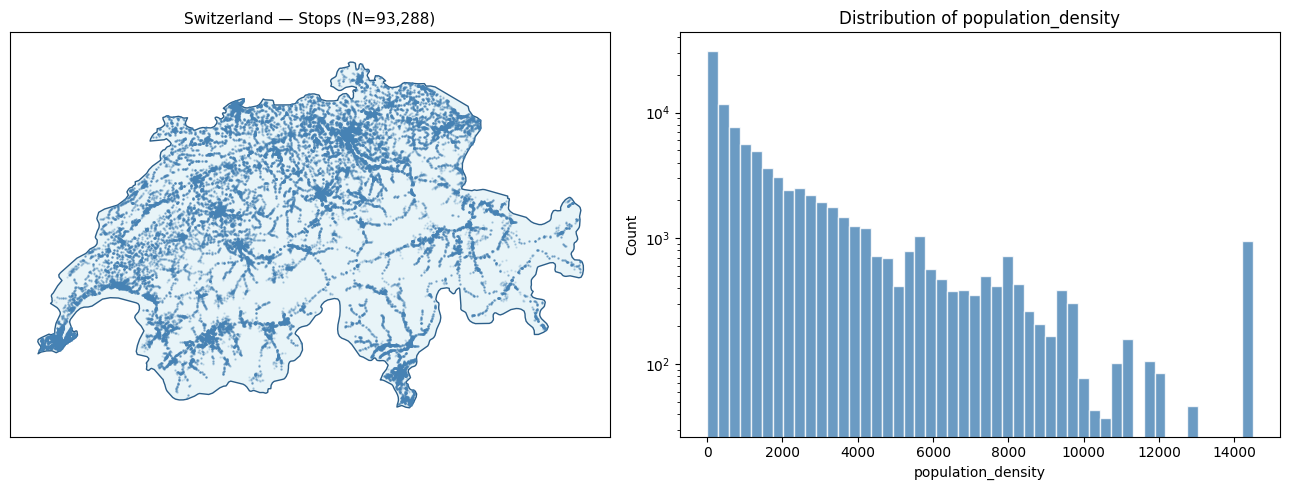

Computing 2PCF for Stops (N=93,288) ...
  N > 10,000 → using bootstrap (10 realizations)
2PCF done.
  γ  = 0.8726 ± 0.0397
  r₀ = 6690 ± 328 m
  D  = 2 − γ = 1.1274
Data sorted by 'population_density' (descending)  — top-3: [19823.38 19823.38 19823.38]


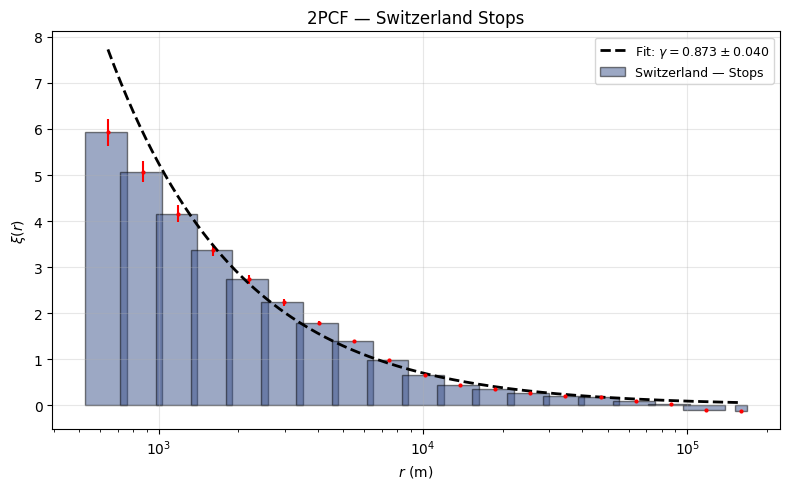

In [4]:
gdf_points    = mtpc.load_df_to_gdf(path_csv, threshold, threshold_variable)
gdf_projected = gdf_points.to_crs(crs)
gdf_projected = gpd.clip(gdf_projected, gdf_edge)

N      = len(gdf_projected)
coords = gdf_projected.get_coordinates().values  # (N, 2) in metres

print(f"N = {N:,} data points")

# ── Spatial map ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
gdf_edge.plot(ax=ax, color="#e8f4f8", edgecolor="#2c5f8a", linewidth=1)
gdf_projected.plot(ax=ax, markersize=0.4, alpha=0.2, color="steelblue")
ax.set_title(f"{name} — {data_type} (N={N:,})", fontsize=11)
ax.axis("equal"); ax.set_xticks([]); ax.set_yticks([])

ax = axes[1]
if threshold_variable in gdf_projected.columns:
    vals = gdf_projected[threshold_variable].dropna()
    ax.hist(vals.clip(upper=vals.quantile(0.99)), bins=50,
            color="steelblue", edgecolor="white", alpha=0.8)
    ax.set_xlabel(threshold_variable); ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {threshold_variable}"); ax.set_yscale("log")

plt.tight_layout(); plt.show()

# ── Adaptive PCF params ───────────────────────────────────────────────────────
if N < 5_000:
    _N_run = N_run;            _size = size;          _k = k
elif N < 30_000:
    _N_run = max(2, N_run//2); _size = min(size, 3_000); _k = 1
else:
    _N_run = 2;               _size = 2_000;         _k = 1

rmin_global = None  # let PCF_with_variance choose

# ── Compute 2PCF of data ──────────────────────────────────────────────────────
print(f"Computing 2PCF for {data_type} (N={N:,}) ...")
if N < bootstrap_size:
    r_edges, l_xi = mtpc.PCF_with_variance(
        gdf_projected, gdf_edge, crs, N_run, size, k, rmax, scale, nbins=nbins)
else:
    print(f"  N > {bootstrap_size:,} → using bootstrap ({bootstrap_N_real} realizations)")
    r_edges, l_xi = mtpc.compute_two_point_correlation_bootstrap(
        gdf_projected, gdf_edge, crs,
        N_run, size, False, rmax, scale, nbins,
        bootstrap_size, bootstrap_N_real)
print("2PCF done.")

# ── Power-law fit ─────────────────────────────────────────────────────────────
gamma, r0, gamma_err, r0_err = fit_2pcf(r_edges, l_xi, a=1, b=19)
if gamma is not None:
    print(f"  γ  = {gamma:.4f} ± {gamma_err:.4f}")
    print(f"  r₀ = {r0:.0f} ± {r0_err:.0f} m")
    print(f"  D  = 2 − γ = {2 - gamma:.4f}")

xi_data = _xi_mean(r_edges, l_xi)

# ── Sort data by threshold_variable descending (high-metadata nodes first) ────
if threshold_variable in gdf_projected.columns:
    meta_vals = gdf_projected[threshold_variable].fillna(0).values
else:
    meta_vals = np.zeros(N)
sort_idx     = np.argsort(meta_vals)[::-1]   # descending
coords_sorted = coords[sort_idx]
print(f"Data sorted by '{threshold_variable}' (descending)  "
      f"— top-3: {meta_vals[sort_idx[:3]]}")

# ── Plot 2PCF ─────────────────────────────────────────────────────────────────
r_plot = r_edges[1:]; xi_plot = xi_data[1:]
err_plot = np.std(l_xi, axis=0)
if len(err_plot) != len(r_edges): err_plot = err_plot[:-1]
err_plot = err_plot[1:]
r_ext = np.append(r_plot, 1.1 * r_plot[-1]); widths = np.diff(r_ext)

fig, ax = plt.subplots(figsize=(8, 5))
c0 = sns.color_palette("viridis", 3)[0]
ax.bar(r_plot, xi_plot, width=widths, align="center",
       edgecolor="black", color=c0, alpha=0.5, label=f"{name} — {data_type}")
ax.errorbar(r_plot, xi_plot, yerr=err_plot, fmt="o", color="red", ms=2)
if gamma is not None:
    r_fit = np.logspace(np.log10(r_plot[0]), np.log10(r_plot[-1]), 300)
    ax.plot(r_fit, power_law(r_fit, gamma, r0), "--", color="black", lw=2,
            label=rf"Fit: $\gamma = {gamma:.3f} \pm {gamma_err:.3f}$")
ax.set_xscale("log"); ax.set_xlabel(r"$r$ (m)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title(f"2PCF — {name} {data_type}"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Choice of η — Silhouette Analysis

The branching factor $\eta$ of the Soneira–Peebles model corresponds to the
**natural number of spatial clusters** in the data.  We determine it by running
$k$-means clustering for $k = 2 \dots k_{\max}$ and picking the $k$ that
maximises the **silhouette score**:

$$\eta^* = \arg\max_k \; s(k)$$

where $s(k) = \frac{b - a}{\max(a, b)}$ ($a$ = intra-cluster distance,
$b$ = nearest-cluster distance).

Silhouette: 100%|██████████| 11/11 [00:12<00:00,  1.15s/it]

Silhouette-optimal η = 12  (score = 0.4794)


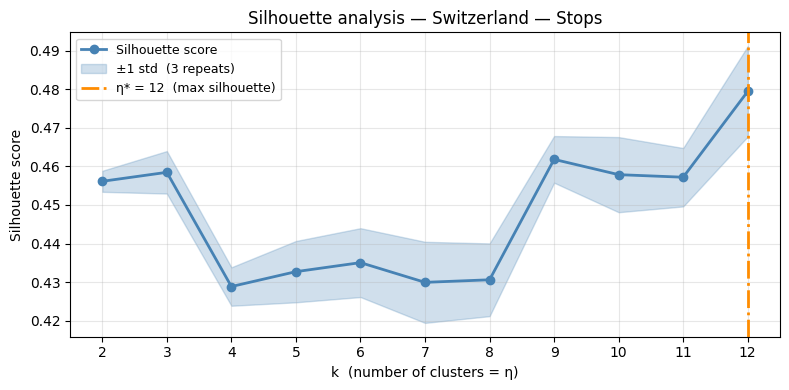

→ η = 12  will be used for pool generation


In [5]:
# ── Silhouette scan ───────────────────────────────────────────────────────────
# silhouette_score computes pairwise distances → O(Nsil²) RAM.
# Keep Nsil ≤ 1500 so each call stays ≈ 18 MB (1500² × 8 bytes).
k_min, k_max = 2, 13
Nsil   = min(1_500, N)      # subsample size — do NOT increase (O(N²) RAM)
n_rep  = 3                  # repeats per k to estimate variance

rng_sil  = np.random.default_rng(1)
k_values = list(range(k_min, k_max))
sil_means, sil_stds = [], []

for k_try in tqdm(k_values, desc="Silhouette"):
    scores = []
    for _ in range(n_rep):
        idx = rng_sil.choice(len(coords), size=Nsil, replace=False)
        c   = coords[idx]
        labels = KMeans(n_clusters=k_try, tol=1e-8, max_iter=200,
                        n_init=10, random_state=0).fit(c).labels_
        scores.append(silhouette_score(c, labels))
    sil_means.append(np.mean(scores))
    sil_stds.append(np.std(scores))

sil_means = np.array(sil_means)
sil_stds  = np.array(sil_stds)

eta = int(k_values[np.argmax(sil_means)])
print(f"Silhouette-optimal η = {eta}  (score = {sil_means[np.argmax(sil_means)]:.4f})")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, sil_means, "o-", color="steelblue", lw=2, ms=6,
        label="Silhouette score")
ax.fill_between(k_values, sil_means - sil_stds, sil_means + sil_stds,
                alpha=0.25, color="steelblue", label=f"±1 std  ({n_rep} repeats)")
ax.axvline(eta, color="darkorange", lw=2, ls="-.",
           label=f"η* = {eta}  (max silhouette)")
ax.set_xlabel("k  (number of clusters = η)")
ax.set_ylabel("Silhouette score")
ax.set_title(f"Silhouette analysis — {name} — {data_type}")
ax.set_xticks(k_values); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"→ η = {eta}  will be used for pool generation")

## 5. m-scan — Find $m^*$ on the Data

The data is sorted by **descending metadata** (population density, traffic…).
The top-$m$ nodes (highest metadata) form sub-population $A$; the remaining
$N-m$ nodes form sub-population $B$.

We compute the **pure cross-correlation** between $A$ and $B$:

$$\xi_{AB}(r) = \frac{N^2\,\xi_{\rm data}(r) - m^2\,\xi_{AA}(r) - (N-m)^2\,\xi_{BB}(r)}{2\,m\,(N-m)}$$

where $\xi_{\rm data}$ is the (already computed) 2PCF of the full dataset — the
union $A\cup B$ is always the same $N$ points regardless of the split.

When the split falls at the **natural boundary** between the fractal sub-population
and the uniform background, $A$ and $B$ become statistically independent and
$\xi_{AB} \approx 0$.  The integral of $|\xi_{AB}|$ therefore has a minimum:

$$m^* = \arg\min_m \int|\xi_{AB}(r)|\,\mathrm{d}r$$

Because $N_A + N_B = N$ (fixed), the prefactor $N^2 / (2\,m(N-m))$ has its
minimum at $m = N/2$, giving a genuine U-shape rather than a monotone curve.

In [6]:
# ── m-scan on data sorted by metadata ─────────────────────────────────────────
# coords_sorted: data sorted by threshold_variable descending (see section 3).
# xi_data / r_edges: already computed full-data 2PCF = ξ_union for every split.
m_min  = max(10, N // 20)
m_max  = N - max(10, N // 20)
n_scan = 40

m_values = np.unique(np.linspace(m_min, m_max, n_scan).astype(int))

# Parameters for cross-2PCF sub-computations (lighter than full 2PCF)
if N < 5_000:
    _x_N_run = N_run;  _x_size = size;    _x_k = k
elif N < 30_000:
    _x_N_run = 2;      _x_size = 2_000;   _x_k = 1
else:
    _x_N_run = 2;      _x_size = 1_500;   _x_k = 1

# ── RAM budget ────────────────────────────────────────────────────────────────
bs_scan     = 3_000
n_jobs_scan = min(n_jobs, 8)

print(f"m-scan on sorted data: {len(m_values)} values in [{m_min:,}, {m_max:,}]")
print(f"Workers: {n_jobs_scan}  bootstrap_size (scan): {bs_scan:,}")

results_m = Parallel(n_jobs=n_jobs_scan)(
    delayed(_run_cross_pcf)(
        int(m), coords_sorted, xi_data, r_edges, gdf_edge, crs,
        _x_N_run, _x_size, _x_k, rmax, scale, nbins,
        bs_scan, bootstrap_N_real
    )
    for m in tqdm(m_values, desc="m-scan")
)

results_m = [r for r in results_m if r is not None]
print(f"{len(results_m)} valid results")

m-scan on sorted data: 40 values in [4,664, 88,624]
Workers: 8  bootstrap_size (scan): 3,000


m-scan: 100%|██████████| 40/40 [00:46<00:00,  1.16s/it]


40 valid results


m* = 56,331  (integral = 17599.7382)
m*/N = 0.604  →  56,331 SP nodes + 36,957 random nodes


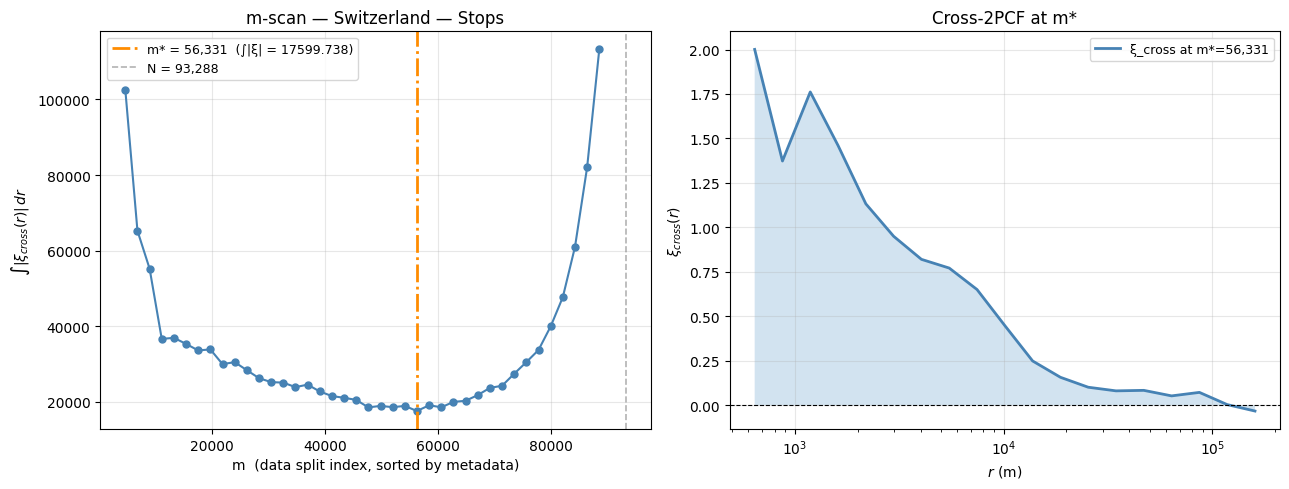

In [7]:
# ── Find m* ───────────────────────────────────────────────────────────────────
m_arr   = np.array([r["m"]        for r in results_m])
int_arr = np.array([r["integral"] for r in results_m])

i_star = int(np.argmin(int_arr))
m_star = int(m_arr[i_star])
int_star = float(int_arr[i_star])

print(f"m* = {m_star:,}  (integral = {int_star:.4f})")
print(f"m*/N = {m_star/N:.3f}  →  {m_star:,} SP nodes + {N - m_star:,} random nodes")

# ── Plot m-scan ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(m_arr, int_arr, "o-", color="steelblue", lw=1.5, ms=5)
ax.axvline(m_star, color="darkorange", lw=2, ls="-.",
           label=f"m* = {m_star:,}  (∫|ξ| = {int_star:.3f})")
ax.axvline(N, color="gray", lw=1.2, ls="--", alpha=0.6, label=f"N = {N:,}")
ax.set_xlabel("m  (data split index, sorted by metadata)"); ax.set_ylabel(r"$\int|\xi_{cross}(r)|\,dr$")
ax.set_title(f"m-scan — {name} — {data_type}"); ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[1]
xi_cross_star = np.array(results_m[i_star]["xi"])
r_cross_star  = np.array(results_m[i_star]["r_edges"])
n_c = min(len(r_cross_star) - 1, len(xi_cross_star))
ax.plot(r_cross_star[1:n_c+1], xi_cross_star[1:n_c+1],
        color="steelblue", lw=2, label=f"ξ_cross at m*={m_star:,}")
ax.axhline(0, color="black", lw=0.8, ls="--")
ax.fill_between(r_cross_star[1:n_c+1], 0, xi_cross_star[1:n_c+1], alpha=0.2)
ax.set_xscale("log"); ax.set_xlabel(r"$r$ (m)"); ax.set_ylabel(r"$\xi_{cross}(r)$")
ax.set_title("Cross-2PCF at m*"); ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 6. Generate SP Pool ($M \gg m^*$)

Now that $m^*$ is known, we generate a Soneira–Peebles pool large enough to
draw $m^*$ representative nodes from it:

$$M = \max(10\,m^*,\;20\,000), \qquad
\lambda = \eta^{\,1/(2-\gamma)}, \qquad
L = \left\lceil\frac{\ln M}{\ln\eta}\right\rceil$$

In [8]:
# ── Build complete SP model (minimum L such that inside-count ≥ m*) ───────────
gamma_sp_target = gamma if gamma is not None else 1.0

print(f"Building SP model: η={eta},  m*={m_star:,} target nodes ...")
pos_sp, L_sp, lamb_sp = build_sp_model(
    m_star, eta, gamma_sp_target, R_ref, gdf_edge, crs)
m_sp = len(pos_sp)

print(f"SP model ready:  η={eta},  λ={lamb_sp:.3f},  L={L_sp},  "
      f"m_SP={m_sp:,} nodes  (target m*={m_star:,})")

Building SP model: η=12,  m*=56,331 target nodes ...
SP model ready:  η=12,  λ=9.062,  L=5,  m_SP=180,945 nodes  (target m*=56,331)


## 6. Verify $\gamma$ of SP($m^*$)

The SP sub-sample pool[:$m^*$] should reproduce the same power-law slope $\gamma$
as the data, since $\gamma$ is a **model parameter** (through $\lambda = \eta^{1/(2-\gamma)}$).

Computing 2PCF of complete SP model  (m_SP=180,945) ...


/home/emery/kDrive/Pro/Code/FakeWorld/fake_world/src/methods_two_point_correlation.py:306: RuntimeWarning: divide by zero encountered in divide
  return (Nr*(Nr_prime-1)*DD)/(Nd*(Nd-1)*RR)-(((Nr_prime-1)*DR)/(Nd*RR))+1
/home/emery/kDrive/Pro/Code/FakeWorld/fake_world/src/methods_two_point_correlation.py:306: RuntimeWarning: invalid value encountered in subtract
  return (Nr*(Nr_prime-1)*DD)/(Nd*(Nd-1)*RR)-(((Nr_prime-1)*DR)/(Nd*RR))+1
/home/emery/kDrive/Pro/Code/FakeWorld/fake_world/src/methods_two_point_correlation.py:306: RuntimeWarning: divide by zero encountered in divide
  return (Nr*(Nr_prime-1)*DD)/(Nd*(Nd-1)*RR)-(((Nr_prime-1)*DR)/(Nd*RR))+1
/home/emery/kDrive/Pro/Code/FakeWorld/fake_world/src/methods_two_point_correlation.py:306: RuntimeWarning: invalid value encountered in subtract
  return (Nr*(Nr_prime-1)*DD)/(Nd*(Nd-1)*RR)-(((Nr_prime-1)*DR)/(Nd*RR))+1
/home/emery/kDrive/Pro/Code/FakeWorld/fake_world/src/methods_two_point_correlation.py:306: RuntimeWarning: divide by zero 

Data  γ = 0.8726 ± 0.0397
SP    γ = 1.1208 ± 0.0819
Δγ      = 0.2482


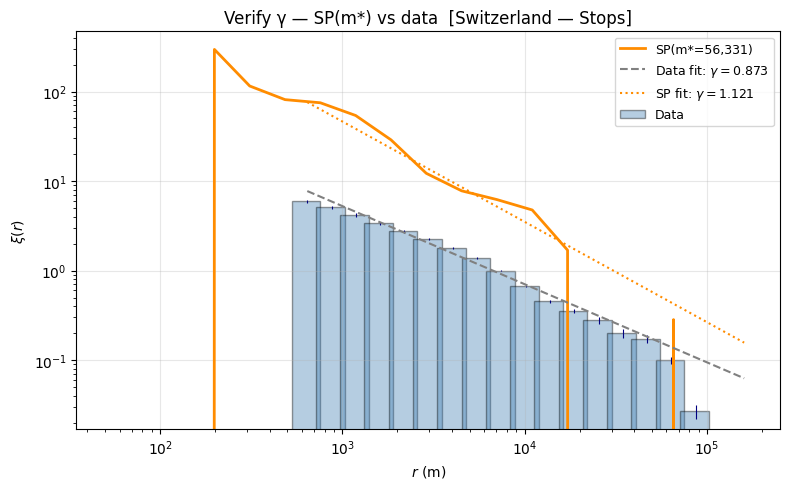

In [12]:
print(f"Computing 2PCF of complete SP model  (m_SP={m_sp:,}) ...")

gdf_sp = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(pos_sp[:, 0], pos_sp[:, 1]), crs=crs)

if m_sp < 5_000:
    _v_N_run = N_run; _v_size = size; _v_k = k
elif m_sp < 30_000:
    _v_N_run = 2;     _v_size = 2_000; _v_k = 1
else:
    _v_N_run = 2;     _v_size = 1_500; _v_k = 1

r_e_sp, l_xi_sp = _pcf_safe(
    gdf_sp, gdf_edge, crs, _v_N_run, _v_size, _v_k,
    rmax, scale, nbins, bootstrap_size, bootstrap_N_real)

xi_sp  = _xi_mean(r_e_sp, l_xi_sp)
r_e_sp = r_e_sp[:len(xi_sp)]   # align (bincount can return variable lengths)

gamma_sp, r0_sp, gamma_sp_err, r0_sp_err = fit_2pcf(r_e_sp, l_xi_sp, a=1, b=19)

print(f"Data  γ = {gamma:.4f} ± {gamma_err:.4f}")
if gamma_sp is not None:
    print(f"SP    γ = {gamma_sp:.4f} ± {gamma_sp_err:.4f}")
    print(f"Δγ      = {abs(gamma - gamma_sp):.4f}")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
r_d = r_edges[1:]; xi_d = xi_data[1:]
err_d = np.std(l_xi, axis=0)
n_err = min(len(err_d), len(r_edges))
err_d = err_d[:n_err]; _r_edges_d = r_edges[:n_err]

r_ext = np.append(r_d, 1.1 * r_d[-1]); w = np.diff(r_ext)
ax.bar(r_d, xi_d, width=w, align="center",
       edgecolor="black", color="steelblue", alpha=0.4, label="Data")
ax.errorbar(r_d, xi_d, yerr=err_d[1:], fmt="none", color="navy", elinewidth=0.8)
ax.plot(r_e_sp[1:], xi_sp[1:], color="darkorange", lw=2,
        label=f"SP(m*={m_star:,})")

r_fit = np.logspace(np.log10(r_d[0]), np.log10(r_d[-1]), 300)
ax.plot(r_fit, power_law(r_fit, gamma, r0), "--", color="gray", lw=1.5,
        label=rf"Data fit: $\gamma={gamma:.3f}$")
if gamma_sp is not None:
    ax.plot(r_fit, power_law(r_fit, gamma_sp, r0_sp), ":", color="darkorange", lw=1.5,
            label=rf"SP fit: $\gamma={gamma_sp:.3f}$")

ax.set_xscale("log"); ax.set_xlabel(r"$r$ (m)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title(f"Verify γ — SP(m*) vs data  [{name} — {data_type}]")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.semilogy()
plt.tight_layout(); plt.show()

## 7. Amplitude Correction — Add Random to Match $\rho$

The SP model (section 6) has the correct **slope** $\gamma$ but its 2PCF
amplitude is generally higher than the data.  We dilute it by adding uniform
random points until the mixture amplitude matches the data:

$$\xi_{\rm mix}(r) \approx \left(\frac{m_{\rm SP}}{m_{\rm SP} + n_{\rm rand}}\right)^2 \xi_{\rm SP}(r)$$

Setting $\xi_{\rm mix} \approx \xi_{\rm data}$ gives the amplitude ratio:

$$\rho = \left\langle \frac{\xi_{\rm data}(r)}{\xi_{\rm SP}(r)} \right\rangle_r, \qquad
n_{\rm rand} = m_{\rm SP}\!\left(\frac{1}{\sqrt{\rho}} - 1\right)$$

This produces a mixture of $N_{\rm total} = m_{\rm SP} + n_{\rm rand}$ nodes
with the correct slope **and** amplitude.  Since $N_{\rm total} > N$ in general,
we then **randomly delete** nodes (SP or random indiscriminately) to reach exactly
$N$ in the next section.

In [10]:
# ── Amplitude ratio ρ ─────────────────────────────────────────────────────────
# The SP model has m_sp nodes.  We add n_rand uniform random nodes so that
# the mixture 2PCF matches the data:
#   ξ_mix ≈ (m_sp / (m_sp + n_rand))² · ξ_SP  ≈  ξ_data
# → ρ = <ξ_data / ξ_SP>_r  →  n_rand = m_sp · (1/√ρ − 1)
xi_sp_aligned = _align(r_e_sp, xi_sp, r_edges)
mask = xi_sp_aligned[1:] > 1e-6   # bins where SP > 0 (xi_data=0 counts as ratio=0)
if mask.sum() > 0:
    rho = float(np.mean(xi_data[1:][mask] / xi_sp_aligned[1:][mask]))
else:
    rho = 1.0
rho = np.clip(rho, 1e-4, 1.0)     # can't exceed 1: adding randoms only lowers amplitude

n_rand  = int(np.round(m_sp * (1.0 / np.sqrt(rho) - 1.0)))
N_total = m_sp + n_rand

print(f"ρ       = {rho:.4f}")
print(f"m_SP    = {m_sp:,}  SP nodes")
print(f"n_rand  = {n_rand:,}  random nodes  (→ N_total = {N_total:,})")
print(f"target  = {N:,}  →  delete {max(0, N_total - N):,} nodes")

# ── Build labelled mixture SP + random ───────────────────────────────────────
terr_geom   = gdf_edge.geometry.union_all()
terr_bounds = terr_geom.bounds

rng_mix       = np.random.default_rng(42)
pos_rand_part = _random_in_territory(n_rand, rng_mix, gdf_edge, crs,
                                     terr_geom, terr_bounds)

pos_mix    = (np.vstack([pos_sp, pos_rand_part])
              if len(pos_rand_part) > 0 else pos_sp.copy())
labels_mix = np.array([0] * len(pos_sp) + [1] * len(pos_rand_part), dtype=np.int8)

print(f"Mixture: {len(pos_mix):,}  ({len(pos_sp):,} SP + {len(pos_rand_part):,} random)")

ρ       = 0.1658
m_SP    = 180,945  SP nodes
n_rand  = 263,380  random nodes  (→ N_total = 444,325)
target  = 93,288  →  delete 351,037 nodes
Mixture: 444,325  (180,945 SP + 263,380 random)


## 8. Final Model — Summary

The last step (random deletion/padding to reach exactly $N$) introduces
stochasticity.  We run it $n_{\rm real}$ times with different seeds and compute
the **mean ± std** of the 2PCF across realisations, giving honest error bars.

Four-panel figure:
1. **Data spatial map**
2. **Model spatial map** (SP in orange, random in green) — last realisation
3. **m-scan curve** with $m^*$ highlighted
4. **2PCF overlay** — data vs model mean ± std

Final model: 93,288 points  (37,965 SP, 55,323 random)  [5 realisations]


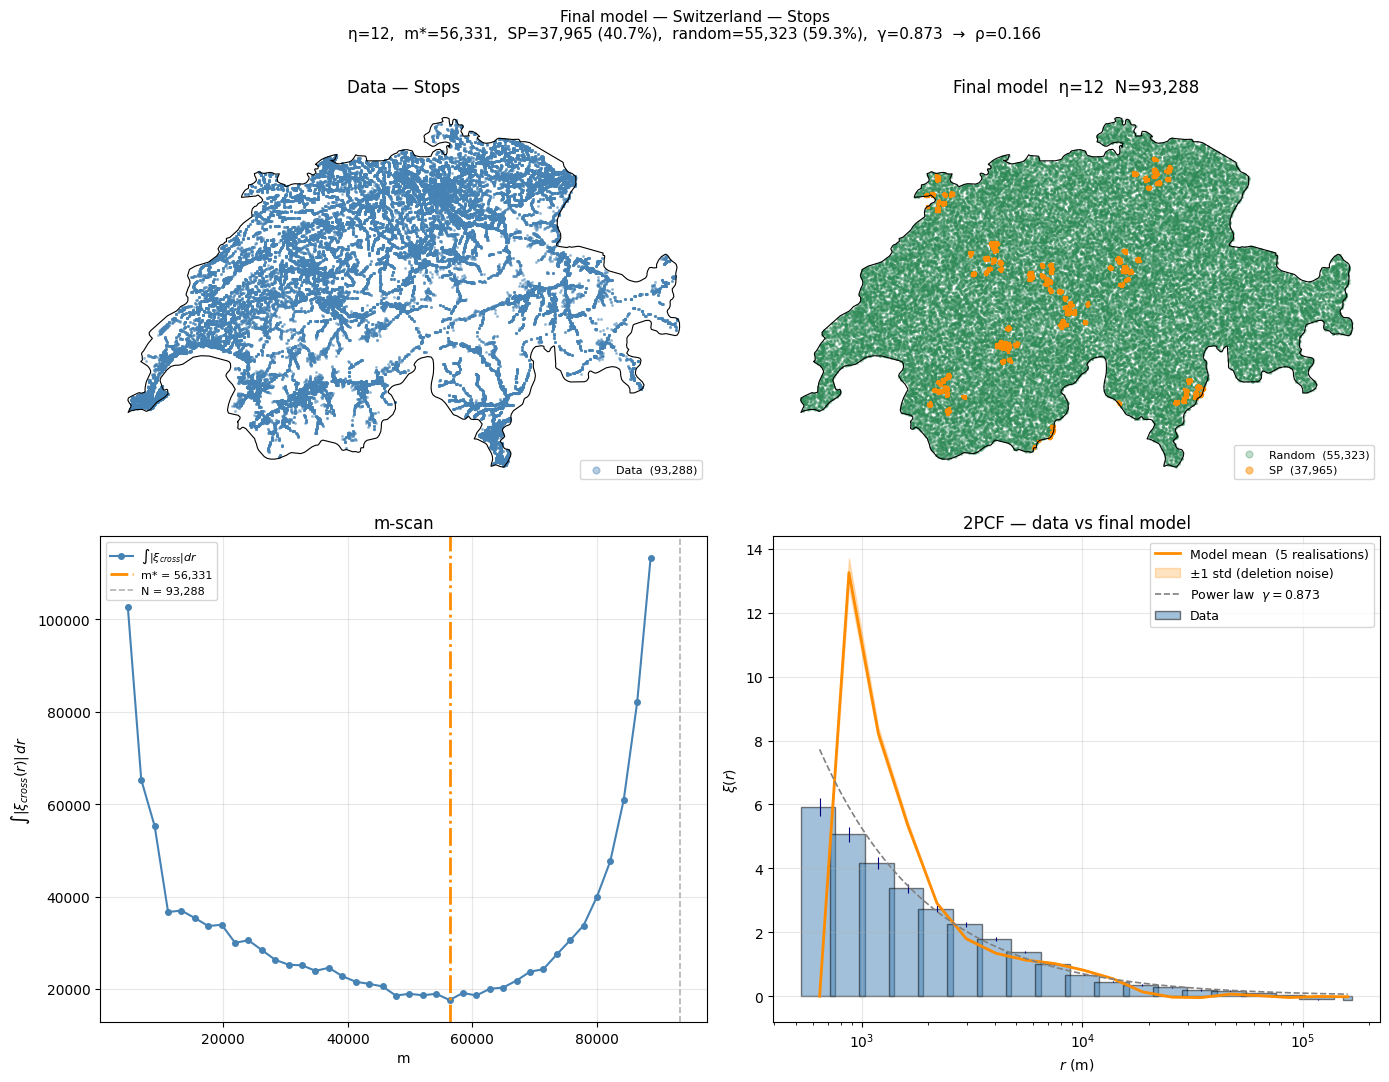

In [11]:
# ── Multiple realisations of the random deletion step ────────────────────────
# pos_mix has N_total points (SP + random).  We randomly delete (N_total − N)
# nodes in each realisation to obtain exactly N points.  Repeating with
# different seeds gives honest error bars on the final 2PCF.
n_real_final = 5

all_xi_final  = []
pos_final     = None
labels_final  = None

for _seed in range(n_real_final):
    rng_f = np.random.default_rng(100 + _seed)

    if len(pos_mix) > N:
        idx   = rng_f.choice(len(pos_mix), size=N, replace=False)
        pos_f = pos_mix[idx]
        lab_f = labels_mix[idx]
    elif len(pos_mix) < N:
        deficit   = N - len(pos_mix)
        pos_extra = _random_in_territory(deficit, rng_f, gdf_edge, crs,
                                         terr_geom, terr_bounds)
        pos_f = np.vstack([pos_mix, pos_extra])
        lab_f = np.concatenate([labels_mix,
                                 np.ones(len(pos_extra), dtype=np.int8)])
    else:
        pos_f = pos_mix.copy()
        lab_f = labels_mix.copy()

    gdf_f = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(pos_f[:, 0], pos_f[:, 1]), crs=crs)
    r_e_f, l_xi_f = _pcf_safe(
        gdf_f, gdf_edge, crs, _x_N_run, _x_size, _x_k,
        rmax, scale, nbins, bootstrap_size, bootstrap_N_real)
    xi_f = _xi_mean(r_e_f, l_xi_f)
    all_xi_final.append(_align(r_e_f, xi_f, r_edges))

    pos_final    = pos_f
    labels_final = lab_f

all_xi_final  = np.array(all_xi_final)   # (n_real_final, nbins)
xi_final_mean = np.mean(all_xi_final, axis=0)
xi_final_std  = np.std(all_xi_final,  axis=0)

pos_final_sp   = pos_final[labels_final == 0]
pos_final_rand = pos_final[labels_final == 1]

print(f"Final model: {len(pos_final):,} points  "
      f"({len(pos_final_sp):,} SP, {len(pos_final_rand):,} random)  "
      f"[{n_real_final} realisations]")

# ── Four-panel figure ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

sp_frac   = 100 * len(pos_final_sp)   / N
rand_frac = 100 * len(pos_final_rand) / N

fig.suptitle(
    f"Final model — {name} — {data_type}\n"
    f"η={eta},  m*={m_star:,},  SP={len(pos_final_sp):,} ({sp_frac:.1f}%),  "
    f"random={len(pos_final_rand):,} ({rand_frac:.1f}%),  "
    f"γ={gamma:.3f}  →  ρ={rho:.3f}",
    fontsize=11)

# Panel (0,0): data map
ax = axes[0, 0]
gdf_edge.boundary.plot(ax=ax, color="black", lw=0.8)
ax.scatter(coords[:, 0], coords[:, 1], s=1.5, color="steelblue", alpha=0.4,
           label=f"Data  ({N:,})")
ax.set_title(f"Data — {data_type}"); ax.axis("off")
ax.legend(fontsize=8, markerscale=4, loc="lower right")

# Panel (0,1): final model map (after trim/pad) — random first, SP on top
ax = axes[0, 1]
gdf_edge.boundary.plot(ax=ax, color="black", lw=0.8)
if len(pos_final_rand) > 0:
    ax.scatter(pos_final_rand[:, 0], pos_final_rand[:, 1],
               s=1.5, color="seagreen", alpha=0.3,
               label=f"Random  ({len(pos_final_rand):,})")
ax.scatter(pos_final_sp[:, 0], pos_final_sp[:, 1],
           s=1.5, color="darkorange", alpha=0.5,
           label=f"SP  ({len(pos_final_sp):,})")
ax.set_title(f"Final model  η={eta}  N={len(pos_final):,}"); ax.axis("off")
ax.legend(fontsize=8, markerscale=4, loc="lower right")

# Panel (1,0): m-scan
ax = axes[1, 0]
ax.plot(m_arr, int_arr, "o-", color="steelblue", lw=1.5, ms=4,
        label=r"$\int|\xi_{cross}|dr$")
ax.axvline(m_star, color="darkorange", lw=2, ls="-.", label=f"m* = {m_star:,}")
ax.axvline(N, color="gray", lw=1.2, ls="--", alpha=0.6, label=f"N = {N:,}")
ax.set_xlabel("m"); ax.set_ylabel(r"$\int|\xi_{cross}(r)|\,dr$")
ax.set_title("m-scan"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

# Panel (1,1): 2PCF overlay with error bars from the n_real realisations
ax = axes[1, 1]
r_d   = r_edges[1:]; xi_d = xi_data[1:]
err_d = np.std(l_xi, axis=0)
if len(err_d) != len(r_edges): err_d = err_d[:-1]
r_ext = np.append(r_d, 1.1 * r_d[-1]); w = np.diff(r_ext)

ax.bar(r_d, xi_d, width=w, align="center",
       edgecolor="black", color="steelblue", alpha=0.5, label="Data")
ax.errorbar(r_d, xi_d, yerr=err_d[1:], fmt="none", color="navy", elinewidth=0.8)

xi_m = xi_final_mean[1:]; xi_s = xi_final_std[1:]
ax.plot(r_d, xi_m, color="darkorange", lw=2,
        label=f"Model mean  ({n_real_final} realisations)")
ax.fill_between(r_d, xi_m - xi_s, xi_m + xi_s,
                color="darkorange", alpha=0.25, label="±1 std (deletion noise)")

r_fit = np.logspace(np.log10(r_d[0]), np.log10(r_d[-1]), 300)
ax.plot(r_fit, power_law(r_fit, gamma, r0), "--", color="gray", lw=1.2,
        label=rf"Power law  $\gamma={gamma:.3f}$")

ax.set_xscale("log"); ax.set_xlabel(r"$r$ (m)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("2PCF — data vs final model")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()